# 06 — So sánh 3 phương pháp trích xuất envelope: Hybrid / Square-Law / FFT Hilbert
Mục tiêu
Với cùng một tín hiệu đầu vào, cùng BPF/LPF và cùng cấu hình đã khóa trong `bandpass_config.json`, notebook đánh giá độ trung thực của hai phương pháp tạo envelope Hybrid và Square-Law so với FFT Hilbert (tham chiếu offline).
Notebook thực hiện:
1. Nạp từng file theo `manifest_clean.csv`; `resample về fs_hz` thống nhất nếu cần.
2. Tạo envelope của cả ba phương pháp trên cùng tín hiệu.
3. Sau warm-up, ước lượng và ghi độ trễ (lag) so với Hilbert; căn chỉnh lag trước khi tính sai số dạng sóng.
4. Tính Pearson, `NRMSE` giữ `DC`, `NRMSE` của thành phần `AC`, MAE trên toàn bộ vùng hợp lệ sau `warm-up` — không chỉ trên đoạn được vẽ.
5. Trên envelope đã giảm mẫu, so sánh phổ tại `BPFO/BPFI/BSF/FTF` và các hài 1–3; ghi biên độ đỉnh lân cận, sai số tuyệt đối/tương đối và sai số dB so với Hilbert.
6. Lưu kết quả theo từng file và bảng tóm tắt; tạo đồ thị minh họa cho một file đại diện mỗi lớp.
Lưu ý: Hilbert là tham chiếu offline, không phải phương pháp triển khai MCU ngang bằng. Kết quả notebook này đo độ trung thực DSP, không đánh giá chất lượng phân loại MLP hay tài nguyên MCU.

In [ ]:
from pathlib import Path
import json
import re

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import butter, sosfilt

from common import io_utils, dsp, config as cfg

# 1. Nạp manifest và cấu hình đã khóa
Đường dẫn được giữ theo cấu trúc notebook giai đoạn 1: `./outputs/tables/manifest_clean.csv` và `bandpass_config.json`. Nếu notebook được chạy từ thư mục khác, sửa `PROJECT_OUTPUT_DIR` bên dưới.

In [11]:
PROJECT_OUTPUT_DIR = Path('./outputs')
TABLES_DIR = PROJECT_OUTPUT_DIR / 'tables'
FIGURES_DIR = PROJECT_OUTPUT_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = TABLES_DIR / 'manifest_clean.csv'
config_path = TABLES_DIR / 'bandpass_config.json'
if not manifest_path.exists():
    raise FileNotFoundError(f'Không tìm thấy {manifest_path}; hãy kiểm tra thư mục làm việc.')
if not config_path.exists():
    raise FileNotFoundError(f'Không tìm thấy {config_path}; hãy chạy notebook tạo cấu hình DSP trước.')

manifest = pd.read_csv(manifest_path)
required_cols = ['file_path', 'label', 'load_hp', 'resolved_sample_rate_hz']
missing_cols = [c for c in required_cols if c not in manifest.columns]
if missing_cols:
    raise ValueError(f'Manifest thiếu cột bắt buộc: {missing_cols}')
if manifest.empty:
    raise ValueError('Manifest không có file để vẽ.')
if manifest['file_path'].isna().any():
    raise ValueError('Manifest có file_path rỗng.')

with open(config_path, encoding='utf-8') as f:
    CONF = json.load(f)

BAND_HZ = tuple(float(v) for v in CONF['band_hz'])
LP_CUTOFF_HZ = float(CONF['lp_cutoff_hz'])
FS = float(CONF['fs_hz'])
WARMUP = int(CONF.get('warmup_samples', 0))
BPF_ORDER = int(CONF.get('bandpass_order', dsp.BENCHMARK_BANDPASS_ORDER))

# Chỉ thay FILE_INDEX để chọn file khác trong manifest.
FILE_INDEX = 12
SEGMENT_SECONDS = 0.05  # thời lượng hiển thị sau warm-up; không ảnh hưởng dữ liệu DSP

manifest = manifest.sort_values(['label', 'file_path']).reset_index(drop=True)
if not 0 <= FILE_INDEX < len(manifest):
    raise IndexError(f'FILE_INDEX phải nằm trong [0, {len(manifest)-1}].')
row = manifest.iloc[FILE_INDEX]

print(f'File {FILE_INDEX + 1}/{len(manifest)}: {row["file_path"]}')
print(f'Nhãn={row["label"]}; tải={row["load_hp"]} HP; nguồn fs={row["resolved_sample_rate_hz"]} Hz')
print(f'BPF={BAND_HZ[0]:g}–{BAND_HZ[1]:g} Hz, bậc={BPF_ORDER}; LPF envelope={LP_CUTOFF_HZ:g} Hz')
print(f'fs={FS:g} Hz; warm-up={WARMUP} mẫu ({1000 * WARMUP / FS:.2f} ms)')


File 13/40: F:\CODE\NCKH_TinyML\TinyML_CWRU\data\raw\12k_Drive_End_Bearing_Fault_Data\IR\007\105_0.mat
Nhãn=IR; tải=0 HP; nguồn fs=12000.0 Hz
BPF=2300–3800 Hz, bậc=4; LPF envelope=750 Hz
fs=12000 Hz; warm-up=2048 mẫu (170.67 ms)


# 3.Tạo ba đường bao trên cùng tín hiệu
Mỗi hàm envelope nhận cùng tín hiệu x và cùng cấu hình BPF/LPF. Tín hiệu nền trên đồ thị là chính tín hiệu rung sau BPF (dải cộng hưởng), vì vậy các đường ±envelope bao quanh đúng thành phần tín hiệu đang được giải điều chế. Đồ thị dùng thời gian gốc, không dịch từng đường để khớp nhau.

In [12]:
METHODS = [
    ('Square-Law', 'square_law', 'tab:blue'),
    ('Hybrid', 'hybrid', 'tab:green'),
    ('FFT Hilbert', 'hilbert_offline', 'tab:orange'),
]


def make_envelope(x, method_key):
    common_kwargs = {
        'band': BAND_HZ,
        'lp_cutoff': LP_CUTOFF_HZ,
        'remove_dc': False,
    }
    if method_key == 'square_law':
        env = dsp.square_law_envelope(x, FS, **common_kwargs)
    elif method_key == 'hybrid':
        env = dsp.hybrid_envelope(x, FS, **common_kwargs)
    elif method_key == 'hilbert_offline':
        env = dsp.hilbert_envelope(x, FS, **common_kwargs)
    else:
        raise ValueError(f'Phương pháp không hợp lệ: {method_key}')

    env = np.asarray(env, dtype=np.float64).reshape(-1)
    if len(env) != len(x):
        raise ValueError(f'{method_key}: độ dài envelope={len(env)}, tín hiệu={len(x)}.')
    if not np.isfinite(env).all():
        raise ValueError(f'{method_key}: envelope có NaN/Inf.')
    return env

source_fs = float(row['resolved_sample_rate_hz'])
x = np.asarray(
    io_utils.load_de_signal_resampled(Path(str(row['file_path'])), source_fs, FS),
    dtype=np.float64,
).reshape(-1)
if not np.isfinite(x).all():
    raise ValueError('Tín hiệu đầu vào có NaN/Inf.')
if len(x) <= WARMUP + 10:
    raise ValueError('Tín hiệu quá ngắn sau warm-up.')

# Tín hiệu miền thời gian cần phủ envelope: BPF Butterworth causal SOS.
bpf_sos = butter(BPF_ORDER, BAND_HZ, btype='bandpass', fs=FS, output='sos')
x_bp = sosfilt(bpf_sos, x)

envelopes = {
    key: make_envelope(x, key)
    for _, key, _ in METHODS
}

for _, key, _ in METHODS:
    if len(envelopes[key]) != len(x_bp):
        raise ValueError(f'{key}: độ dài không khớp với tín hiệu BPF.')

print(f'Đã tính {len(METHODS)} envelope trên cùng {len(x):,} mẫu.')


Đã tính 3 envelope trên cùng 121,265 mẫu.


# 4. Phổ envelope
Envelope được giảm mẫu trên **toàn file trước khi bỏ warm-up**, tránh khởi tạo lại decimator tại đầu đoạn phân tích. Sau đó các envelope được căn chỉnh với Hilbert, trừ DC, rồi dùng cùng hàm FFT/cửa sổ. Ba phương pháp dùng **một đỉnh phổ chung cho mỗi file** để chuẩn hóa; không chuẩn hóa riêng từng phổ.
Với mỗi `BPFO/BPFI/BSF/FTF` và hài 1–3, tìm đỉnh cục bộ trong vùng `±SEARCH_WIDTH_HZ` quanh tần số lý thuyết. Bảng theo file lưu biên độ của Hybrid/Square-Law, biên độ Hilbert, sai số tuyệt đối, sai số tương đối và sai số dB. Sai số tương đối/dB không báo khi đỉnh Hilbert quá gần 0 theo ngưỡng `REL_ERROR_FLOOR`, vì khi đó tỷ số không ổn định.

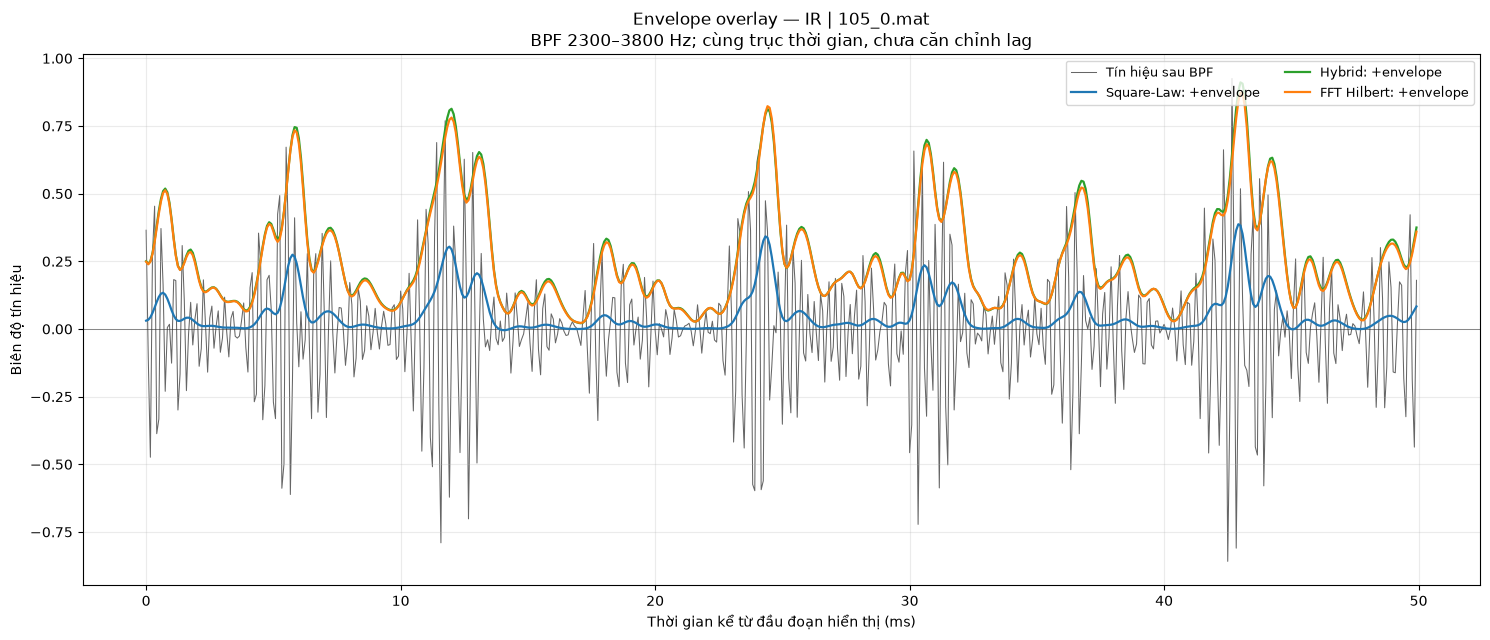

Đã lưu hình: outputs\figures\06_envelope_overlay_105_0.png


In [13]:
start = WARMUP
n_plot = min(int(round(SEGMENT_SECONDS * FS)), len(x) - start)
if n_plot <= 10:
    raise ValueError('Đoạn tín hiệu sau warm-up quá ngắn để vẽ.')
stop = start + n_plot

time_ms = np.arange(n_plot, dtype=np.float64) * 1000.0 / FS
x_seg = x_bp[start:stop]

fig, ax = plt.subplots(figsize=(15, 6.5))
ax.plot(
    time_ms, x_seg,
    color='0.25', linewidth=0.75, alpha=0.8,
    label='Tín hiệu sau BPF', zorder=1,
)

for name, key, color in METHODS:
    env_seg = envelopes[key][start:stop]
    ax.plot(
        time_ms, env_seg,
        color=color, linewidth=1.6, linestyle='-',
        label=f'{name}: +envelope', zorder=3,
    )
    
ax.axhline(0.0, color='black', linewidth=0.6, alpha=0.5)
ax.set_title(
    f'Envelope overlay — {row["label"]} | {Path(str(row["file_path"])).name}\n'
    f'BPF {BAND_HZ[0]:g}–{BAND_HZ[1]:g} Hz; cùng trục thời gian, chưa căn chỉnh lag'
)
ax.set_xlabel('Thời gian kể từ đầu đoạn hiển thị (ms)')
ax.set_ylabel('Biên độ tín hiệu')
ax.grid(True, alpha=0.25)
ax.legend(ncol=2, fontsize=9, loc='upper right')
fig.tight_layout()

safe_stem = re.sub(r'[^A-Za-z0-9._-]+', '_', Path(str(row['file_path'])).stem)
figure_path = FIGURES_DIR / f'06_envelope_overlay_{safe_stem}.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Đã lưu hình: {figure_path}')


# 4. Benchmark dạng sóng trên toàn bộ manifest
Benchmark lặp lại việc tạo envelope cho mọi dòng trong `manifest_clean.csv`, không chỉ `FILE_INDEX`. Với mỗi file, dùng` FFT Hilbert` làm tham chiếu; sau `warm-up`, ước lượng lag của `Square-Law/Hybrid`, căn chỉnh vùng chồng lấp rồi tính `Pearson`, `MAE, RMSE, NRMSE` giữ` DC` và `NRMSE` của thành phần` AC`. `Lag` được lưu riêng để việc căn chỉnh không che mất độ trễ.

In [14]:
# Tham số benchmark. Không thay đổi cấu hình DSP đã khóa.
MAX_LAG_SAMPLES = 100       # giới hạn tìm lag ở fs đầu vào
FMAX_HZ = 500.0             # dải envelope dùng để tìm/so đỉnh phổ
SEARCH_WIDTH_HZ = 3.0       # tìm đỉnh cục bộ trong ±3 Hz quanh tần số lý thuyết
HARMONICS = (1, 2, 3)
REL_ERROR_FLOOR = 1e-3      # tránh %/dB khi đỉnh Hilbert gần 0 sau chuẩn hóa
REFERENCE_KEY = 'hilbert_offline'
FAULT_NAMES = ('BPFO', 'BPFI', 'BSF', 'FTF')


def estimate_lag(candidate, reference, warmup_samples, max_lag_samples):
    """Ước lượng lag nguyên mẫu; lag > 0 nghĩa candidate trễ hơn reference."""
    candidate = np.asarray(candidate, dtype=np.float64).reshape(-1)
    reference = np.asarray(reference, dtype=np.float64).reshape(-1)
    if len(candidate) != len(reference):
        raise ValueError('Candidate và reference phải có cùng độ dài trước khi tìm lag.')
    if min(len(candidate), len(reference)) <= warmup_samples + max_lag_samples + 10:
        raise ValueError('Tín hiệu quá ngắn để tìm lag sau warm-up.')

    a = candidate[warmup_samples:]
    b = reference[warmup_samples:]
    best_lag, best_corr = 0, -np.inf
    for lag in range(-int(max_lag_samples), int(max_lag_samples) + 1):
        # So sánh candidate[i + lag] với reference[i].
        if lag >= 0:
            aa = a[lag:]
            bb = b[:len(b) - lag] if lag else b
        else:
            aa = a[:len(a) + lag]
            bb = b[-lag:]
        n = min(len(aa), len(bb))
        if n <= 10:
            continue
        aa = aa[:n] - np.mean(aa[:n])
        bb = bb[:n] - np.mean(bb[:n])
        denom = float(np.linalg.norm(aa) * np.linalg.norm(bb))
        corr = float(np.dot(aa, bb) / denom) if denom > 1e-20 else -np.inf
        if corr > best_corr:
            best_lag, best_corr = lag, corr
    if not np.isfinite(best_corr):
        raise ValueError('Không ước lượng được lag; tín hiệu có thể gần hằng số.')
    return int(best_lag), float(best_corr)


def align_to_reference(series_by_key, reference_key, warmup_samples, max_lag_samples):
    """Căn chỉnh candidate với Hilbert; trả vùng chồng lấp nằm sau warm-up."""
    ref = np.asarray(series_by_key[reference_key], dtype=np.float64).reshape(-1)
    lags = {reference_key: 0}
    lag_corrs = {reference_key: 1.0}
    for _, key, _ in METHODS:
        if key == reference_key:
            continue
        lag, corr = estimate_lag(series_by_key[key], ref, warmup_samples, max_lag_samples)
        lags[key], lag_corrs[key] = lag, corr

    ref_start = int(warmup_samples - min(lags.values()))
    ref_end = min(len(ref), *(len(np.asarray(series_by_key[k])) - lags[k] for _, k, _ in METHODS))
    if ref_end <= ref_start:
        raise ValueError('Không còn vùng chồng lấp sau warm-up và căn chỉnh lag.')

    aligned = {
        key: np.asarray(series_by_key[key], dtype=np.float64)[
            ref_start + lags[key]:ref_end + lags[key]
        ]
        for _, key, _ in METHODS
    }
    if len({len(v) for v in aligned.values()}) != 1:
        raise RuntimeError('Lỗi căn chỉnh: độ dài các envelope không bằng nhau.')
    return aligned, lags, lag_corrs


def rms(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.sqrt(np.mean(values ** 2))) if len(values) else np.nan


def safe_pearson(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    if len(a) < 2 or np.std(a) <= 1e-20 or np.std(b) <= 1e-20:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])


def safe_int(value):
    return None if value is None or pd.isna(value) else int(value)


def get_rpm(row):
    """Ưu tiên RPM đã khóa trong manifest; fallback theo tải danh định khi cần."""
    for col in ('rpm', 'rpm_from_file'):
        value = row.get(col)
        if value is not None and not pd.isna(value):
            value = float(value)
            if np.isfinite(value) and value > 0:
                return value
    load_value = row.get('load_hp')
    if load_value is None or pd.isna(load_value):
        raise ValueError('Không có RPM hợp lệ và manifest thiếu load_hp để fallback.')
    load = int(load_value)
    if load not in cfg.NOMINAL_RPM_BY_LOAD:
        raise ValueError(f'Không có RPM hợp lệ trong manifest và không có RPM danh định cho tải {load} HP.')
    return float(cfg.NOMINAL_RPM_BY_LOAD[load])


def slug(value):
    value = re.sub(r'[^A-Za-z0-9._-]+', '_', str(value).strip())
    return value.strip('._-') or 'unknown'


def metrics_for_waveforms(case, aligned, lags, lag_corrs):
    """Metrics trên toàn vùng hợp lệ sau warm-up/căn chỉnh, không phụ thuộc đoạn vẽ."""
    ref = np.asarray(aligned[REFERENCE_KEY], dtype=np.float64)
    ref_ac = ref - np.mean(ref)
    ref_rms = rms(ref)
    ref_ac_rms = rms(ref_ac)
    rows = []
    eps = 1e-12

    for method_name, key, _ in METHODS:
        env = np.asarray(aligned[key], dtype=np.float64)
        env_ac = env - np.mean(env)
        err = env - ref
        err_ac = env_ac - ref_ac
        lag = int(lags[key])
        rows.append({
            'case_id': case['case_id'],
            'file_path': case['file_path'],
            'filename': case['filename'],
            'label': case['label'],
            'load_hp': case['load_hp'],
            'fault_diameter_mils': case['fault_diameter_mils'],
            'source_fs_hz': case['source_fs_hz'],
            'fs_hz': FS,
            'method': method_name,
            'method_key': key,
            'reference_method': METHODS[2][0],
            'n_samples_compared_after_warmup': len(env),
            'lag_samples_vs_hilbert': lag,
            'lag_ms_vs_hilbert': 1000.0 * lag / FS,
            'alignment_correlation_at_lag': float(lag_corrs[key]),
            'pearson_vs_hilbert': safe_pearson(env, ref),
            'mae_envelope': float(np.mean(np.abs(err))),
            'rmse_envelope': rms(err),
            'nrmse_envelope_preserve_dc': rms(err) / max(ref_rms, eps),
            'nrmse_ac_shape_only': rms(err_ac) / max(ref_ac_rms, eps),
            'envelope_mean': float(np.mean(env)),
            'envelope_rms': rms(env),
            'envelope_ac_rms': rms(env_ac),
        })
    return pd.DataFrame(rows)


# 5. Benchmark phổ envelope tại tần số lỗi
Envelope của cả ba phương pháp được giảm mẫu trên toàn file trước khi bỏ `warm-up`. Sau đó căn chỉnh `lag `trên miền envelope, tính phổ AC bằng cùng hàm FFT và chuẩn hóa bằng một đỉnh chung trong dải `0–FMAX_HZ` cho cả ba phương pháp của cùng file. Tại `BPFO/BPFI/BSF/FTF` và các hài 1–3, lưu tần số đỉnh cục bộ và sai số biên độ so với Hilbert.

In [15]:
def peak_near_frequency(freqs, magnitude, target_hz, search_width_hz, fmax_hz):
    """Trả về tần số đỉnh cục bộ và biên độ; NaN nếu tần số ngoài dải."""
    freqs = np.asarray(freqs, dtype=np.float64)
    magnitude = np.asarray(magnitude, dtype=np.float64)
    if len(freqs) == 0 or not np.isfinite(target_hz) or target_hz <= 0:
        return np.nan, np.nan
    if target_hz > min(fmax_hz, float(freqs[-1])):
        return np.nan, np.nan
    mask = (
        (freqs >= max(0.0, target_hz - search_width_hz))
        & (freqs <= min(fmax_hz, target_hz + search_width_hz))
    )
    idxs = np.flatnonzero(mask)
    if len(idxs) == 0:
        return np.nan, np.nan
    idx = idxs[int(np.nanargmax(magnitude[idxs]))]
    return float(freqs[idx]), float(magnitude[idx])


def spectrum_metrics(case, envelopes):
    """So phổ envelope sau decimate tại BPFO/BPFI/BSF/FTF và hài 1–3."""
    decimated = {}
    fs_env = None
    for _, key, _ in METHODS:
        env_d, fs_current = dsp.decimate_envelope(envelopes[key], FS)
        env_d = np.asarray(env_d, dtype=np.float64).reshape(-1)
        if not np.isfinite(env_d).all():
            raise ValueError(f'{key}: envelope sau decimate có NaN/Inf.')
        if fs_env is None:
            fs_env = float(fs_current)
        elif not np.isclose(fs_env, float(fs_current)):
            raise ValueError('Tần số lấy mẫu envelope không đồng nhất giữa các phương pháp.')
        decimated[key] = env_d

    if len({len(v) for v in decimated.values()}) != 1:
        raise ValueError('Độ dài envelope sau decimate không đồng nhất.')
    warmup_env = int(math.ceil(WARMUP * fs_env / FS))
    max_lag_env = max(1, int(math.ceil(MAX_LAG_SAMPLES * fs_env / FS)))
    aligned, lags, lag_corrs = align_to_reference(
        decimated, REFERENCE_KEY, warmup_env, max_lag_env
    )

    fmax_hz = min(float(FMAX_HZ), fs_env / 2.0)
    spectra = {}
    for method_name, key, _ in METHODS:
        env = np.asarray(aligned[key], dtype=np.float64)
        env_ac = env - np.mean(env)
        freqs, mag = dsp.compute_fft(env_ac, fs_env, apply_window=True)
        freqs = np.asarray(freqs, dtype=np.float64)
        mag = np.asarray(mag, dtype=np.float64)
        if len(freqs) != len(mag) or len(freqs) < 2:
            raise ValueError(f'FFT không hợp lệ cho {key}.')
        band_mask = (freqs >= 0.0) & (freqs <= fmax_hz)
        if not np.any(band_mask):
            raise ValueError(f'Không có bin FFT trong dải 0–{fmax_hz:g} Hz.')
        spectra[key] = {
            'method': method_name,
            'env_ac': env_ac,
            'freqs': freqs,
            'mag': mag,
            'band_mask': band_mask,
            'lag_env_samples': int(lags[key]),
            'lag_env_ms': 1000.0 * int(lags[key]) / fs_env,
            'lag_corr': float(lag_corrs[key]),
            'fs_env_hz': fs_env,
        }

    # Chuẩn hóa bằng một đỉnh chung cho cả ba phương pháp trên cùng file.
    common_peak = max(float(np.max(s['mag'][s['band_mask']])) for s in spectra.values())
    if not np.isfinite(common_peak) or common_peak <= 1e-20:
        raise ValueError('Không có đỉnh phổ hợp lệ để chuẩn hóa.')
    for s in spectra.values():
        s['mag_common_norm'] = s['mag'] / common_peak

    fault_rows = []
    faults = case['faults']
    ref_spec = spectra[REFERENCE_KEY]
    eps = 1e-12
    for fault_name in FAULT_NAMES:
        if fault_name not in faults:
            continue
        base_hz = float(faults[fault_name])
        for harmonic in HARMONICS:
            target_hz = base_hz * harmonic
            ref_peak_hz, ref_amp = peak_near_frequency(
                ref_spec['freqs'], ref_spec['mag_common_norm'],
                target_hz, SEARCH_WIDTH_HZ, fmax_hz,
            )
            for method_name, key, _ in METHODS:
                spec = spectra[key]
                peak_hz, amp = peak_near_frequency(
                    spec['freqs'], spec['mag_common_norm'],
                    target_hz, SEARCH_WIDTH_HZ, fmax_hz,
                )
                valid = np.isfinite(amp) and np.isfinite(ref_amp)
                signed_err = float(amp - ref_amp) if valid else np.nan
                abs_err = float(abs(signed_err)) if valid else np.nan
                if valid and ref_amp >= REL_ERROR_FLOOR:
                    rel_err_pct = 100.0 * signed_err / ref_amp
                    error_db = 20.0 * np.log10(max(float(amp), eps) / max(float(ref_amp), eps))
                else:
                    rel_err_pct, error_db = np.nan, np.nan
                fault_rows.append({
                    'case_id': case['case_id'],
                    'file_path': case['file_path'],
                    'filename': case['filename'],
                    'label': case['label'],
                    'load_hp': case['load_hp'],
                    'fault_diameter_mils': case['fault_diameter_mils'],
                    'rpm': case['rpm'],
                    'method': method_name,
                    'method_key': key,
                    'reference_method': METHODS[2][0],
                    'fault_component': fault_name,
                    'harmonic': harmonic,
                    'target_frequency_hz': target_hz,
                    'search_width_hz': SEARCH_WIDTH_HZ,
                    'observed_peak_frequency_hz': peak_hz,
                    'reference_peak_frequency_hz': ref_peak_hz,
                    'peak_frequency_error_hz': peak_hz - target_hz if np.isfinite(peak_hz) else np.nan,
                    'amplitude_common_norm': amp,
                    'reference_amplitude_common_norm': ref_amp,
                    'signed_error_common_norm': signed_err,
                    'absolute_error_common_norm': abs_err,
                    'relative_error_pct': rel_err_pct,
                    'error_db_vs_hilbert': error_db,
                    'reference_floor_used_for_relative_error': REL_ERROR_FLOOR,
                    'fs_envelope_hz': fs_env,
                    'fft_bin_hz': float(spec['freqs'][1] - spec['freqs'][0]),
                    'alignment_lag_env_samples_vs_hilbert': spec['lag_env_samples'],
                    'alignment_lag_env_ms_vs_hilbert': spec['lag_env_ms'],
                    'alignment_correlation_at_lag': spec['lag_corr'],
                })
    return pd.DataFrame(fault_rows)


# 6. Chạy benchmark trên toàn bộ manifest và lưu CSV
Nếu một file lỗi đọc hoặc xử lý, notebook ghi lỗi vào CSV và tiếp tục file tiếp theo để có báo cáo chẩn đoán đầy đủ. Không được coi benchmark là hoàn tất nếu 06_dsp_benchmark_errors.csv còn dòng lỗi hoặc số file thành công nhỏ hơn số dòng trong manifest. Chỉ sinh một đồ thị overlay cho file FILE_INDEX ở phần trước; benchmark toàn manifest không sinh hàng loạt hình.

In [19]:
# Chạy benchmark trên TOÀN BỘ manifest; FILE_INDEX chỉ tác động đến hình minh họa phía trên.
waveform_tables = []
spectrum_tables = []
error_rows = []
processed_cases = 0

for manifest_idx, row_bench in manifest.iterrows():
    file_path = str(row_bench['file_path'])
    try:
        source_fs = float(row_bench['resolved_sample_rate_hz'])
        x_bench = np.asarray(
            io_utils.load_de_signal_resampled(Path(file_path), source_fs, FS),
            dtype=np.float64,
        ).reshape(-1)
        if not np.isfinite(x_bench).all():
            raise ValueError('Tín hiệu đầu vào có NaN/Inf.')
        if len(x_bench) <= WARMUP + MAX_LAG_SAMPLES + 10:
            raise ValueError('File quá ngắn sau warm-up để đo lag/metrics.')

        env_bench = {key: make_envelope(x_bench, key) for _, key, _ in METHODS}
        aligned_bench, lags_bench, lag_corr_bench = align_to_reference(
            env_bench, REFERENCE_KEY, WARMUP, MAX_LAG_SAMPLES
        )

        label = str(row_bench['label'])
        load_value = row_bench.get('load_hp')
        load_hp = safe_int(load_value)
        diameter = safe_int(row_bench.get('fault_diameter_mils'))
        rpm = get_rpm(row_bench)
        fault_freqs = cfg.bearing_fault_frequencies(rpm)
        normalized_path = file_path.replace('\\', '/')
        filename = Path(normalized_path).name
        diameter_tag = 'na' if diameter is None else str(diameter)
        case_id = f'{int(manifest_idx):04d}_{slug(label)}_{slug(Path(filename).stem)}'
        case = {
            'case_id': case_id,
            'file_path': file_path,
            'filename': filename,
            'label': label,
            'load_hp': load_hp,
            'fault_diameter_mils': diameter,
            'source_fs_hz': source_fs,
            'rpm': rpm,
            'faults': {str(k): float(v) for k, v in fault_freqs.items()
                       if np.isfinite(float(v))},
        }

        wave_df = metrics_for_waveforms(case, aligned_bench, lags_bench, lag_corr_bench)
        spec_df = spectrum_metrics(case, env_bench)
        waveform_tables.append(wave_df)
        spectrum_tables.append(spec_df)
        processed_cases += 1

        if processed_cases % 5 == 0 or processed_cases == len(manifest):
            print(f'Đã benchmark {processed_cases}/{len(manifest)} file...')

    except Exception as exc:
        error_rows.append({
            'manifest_row_index': int(manifest_idx),
            'file_path': file_path,
            'label': str(row_bench.get('label', '')),
            'error_type': type(exc).__name__,
            'error_message': str(exc),
        })
        print(f'[LỖI] {file_path}: {type(exc).__name__}: {exc}')

# Export waveform metrics and method-level summary.
if waveform_tables:
    waveform_by_file = pd.concat(waveform_tables, ignore_index=True)
    waveform_path = TABLES_DIR / '06_waveform_metrics_by_file.csv'
    waveform_by_file.to_csv(waveform_path, index=False, encoding='utf-8-sig')

    waveform_summary = (
        waveform_by_file.groupby(['method', 'method_key'], as_index=False)
        .agg(
            n_files=('case_id', 'nunique'),
            pearson_mean=('pearson_vs_hilbert', 'mean'),
            pearson_std=('pearson_vs_hilbert', 'std'),
            nrmse_envelope_mean=('nrmse_envelope_preserve_dc', 'mean'),
            nrmse_envelope_median=('nrmse_envelope_preserve_dc', 'median'),
            nrmse_ac_mean=('nrmse_ac_shape_only', 'mean'),
            nrmse_ac_median=('nrmse_ac_shape_only', 'median'),
            mae_mean=('mae_envelope', 'mean'),
            lag_samples_mean=('lag_samples_vs_hilbert', 'mean'),
            lag_samples_abs_median=('lag_samples_vs_hilbert', lambda s: float(np.median(np.abs(s)))),
        )
    )
    waveform_summary_path = TABLES_DIR / '06_waveform_metrics_summary_by_method.csv'
    waveform_summary.to_csv(waveform_summary_path, index=False, encoding='utf-8-sig')
    print('\nTóm tắt metrics dạng sóng theo phương pháp:')
    display(waveform_summary)
    print('Đã lưu:', waveform_path)
    print('Đã lưu:', waveform_summary_path)
else:
    waveform_by_file = pd.DataFrame()
    print('Không có file nào hoàn tất waveform metrics.')

# Export fault-frequency spectrum errors and summary.
if spectrum_tables:
    spectrum_errors_by_file = pd.concat(spectrum_tables, ignore_index=True)
    spectrum_path = TABLES_DIR / '06_fault_spectrum_errors_by_file.csv'
    spectrum_errors_by_file.to_csv(spectrum_path, index=False, encoding='utf-8-sig')

    candidates = spectrum_errors_by_file[spectrum_errors_by_file['method_key'] != REFERENCE_KEY]
    spectrum_summary = (
        candidates.groupby(['method', 'method_key', 'fault_component', 'harmonic'], as_index=False)
        .agg(
            n_files=('case_id', 'nunique'),
            mean_abs_error_common_norm=('absolute_error_common_norm', 'mean'),
            median_abs_error_common_norm=('absolute_error_common_norm', 'median'),
            median_abs_relative_error_pct=('relative_error_pct', lambda s: float(np.nanmedian(np.abs(s))) if np.isfinite(s).any() else np.nan),
            median_abs_error_db=('error_db_vs_hilbert', lambda s: float(np.nanmedian(np.abs(s))) if np.isfinite(s).any() else np.nan),
        )
    )
    spectrum_summary_path = TABLES_DIR / '06_fault_spectrum_error_summary.csv'
    spectrum_summary.to_csv(spectrum_summary_path, index=False, encoding='utf-8-sig')
    print('\nTóm tắt sai số phổ tại tần số lỗi/hài:')
    display(spectrum_summary)
    print('Đã lưu:', spectrum_path)
    print('Đã lưu:', spectrum_summary_path)
else:
    spectrum_errors_by_file = pd.DataFrame()
    print('Không có file nào hoàn tất spectrum metrics.')

errors_path = TABLES_DIR / '06_dsp_benchmark_errors.csv'
errors_df = pd.DataFrame(error_rows, columns=[
    'manifest_row_index', 'file_path', 'label', 'error_type', 'error_message'
])
errors_df.to_csv(errors_path, index=False, encoding='utf-8-sig')

print(f'\nHoàn tất: {processed_cases}/{len(manifest)} file thành công; {len(error_rows)} file lỗi.')
print('Danh sách lỗi:', errors_path)
if error_rows:
    display(errors_df)
    print('CẢNH BÁO: benchmark chưa đầy đủ; cần xử lý tất cả lỗi rồi chạy lại.')
else:
    print('Benchmark đã xử lý toàn bộ manifest mà không ghi nhận lỗi.')


Đã benchmark 5/40 file...
Đã benchmark 10/40 file...
Đã benchmark 15/40 file...
Đã benchmark 20/40 file...
Đã benchmark 25/40 file...
Đã benchmark 30/40 file...
Đã benchmark 35/40 file...
Đã benchmark 40/40 file...

Tóm tắt metrics dạng sóng theo phương pháp:


,method,method_key,n_files,pearson_mean,pearson_std,nrmse_envelope_mean,nrmse_envelope_median,nrmse_ac_mean,nrmse_ac_median,mae_mean,lag_samples_mean,lag_samples_abs_median
0,FFT Hilbert,hilbert_offline,40,1.000000,8.709306e-17,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
1,Hybrid,hybrid,40,0.999724,2.219480e-04,0.028596,0.027969,0.034744,0.034280,0.006547,0.0,0.0
2,Square-Law,square_law,40,0.930167,3.586272e-02,0.741296,0.770120,0.675546,0.716939,0.160401,-1.0,1.0


Đã lưu: outputs\tables\06_waveform_metrics_by_file.csv
Đã lưu: outputs\tables\06_waveform_metrics_summary_by_method.csv

Tóm tắt sai số phổ tại tần số lỗi/hài:


,method,method_key,fault_component,harmonic,n_files,mean_abs_error_common_norm,median_abs_error_common_norm,median_abs_relative_error_pct,median_abs_error_db
0,Hybrid,hybrid,BPFI,1,40,0.015630,0.018126,2.484047,0.213125
1,Hybrid,hybrid,BPFI,2,40,0.007271,0.005832,1.953043,0.168004
2,Hybrid,hybrid,BPFI,3,40,0.006086,0.004016,3.006523,0.257295
3,Hybrid,hybrid,BPFO,1,40,0.011474,0.011439,2.862402,0.245133
4,Hybrid,hybrid,BPFO,2,40,0.006908,0.004149,2.124379,0.182588
5,Hybrid,hybrid,BPFO,3,40,0.007409,0.006088,1.972529,0.169664
6,Hybrid,hybrid,BSF,1,40,0.009289,0.009990,2.812185,0.240892
7,Hybrid,hybrid,BSF,2,40,0.004551,0.002085,2.596757,0.222672
8,Hybrid,hybrid,BSF,3,40,0.003261,0.001484,2.546408,0.218405
9,Hybrid,hybrid,FTF,1,40,0.009735,0.006045,2.843597,0.243544


Đã lưu: outputs\tables\06_fault_spectrum_errors_by_file.csv
Đã lưu: outputs\tables\06_fault_spectrum_error_summary.csv

Hoàn tất: 40/40 file thành công; 0 file lỗi.
Danh sách lỗi: outputs\tables\06_dsp_benchmark_errors.csv
Benchmark đã xử lý toàn bộ manifest mà không ghi nhận lỗi.


# Đầu ra CSV
Các file CSV được lưu trong `outputs/tables/`:
- `06_waveform_metrics_by_file.csv`: một dòng cho mỗi file × phương pháp; chứa `Pearson, MAE, RMSE, NRMSE và lag.`
- `06_waveform_metrics_summary_by_method.csv`: tóm tắt metrics dạng sóng trên toàn bộ các file xử lý thành công.
- `06_fault_spectrum_errors_by_file.csv`: sai số phổ theo file × phương pháp × thành phần lỗi × hài.
- `06_fault_spectrum_error_summary.csv`: tóm tắt sai số phổ của `Square-Law` và `Hybrid` theo thành phần lỗi/hài.
- `06_dsp_benchmark_errors.csv`: file không xử lý được và nguyên nhân; cần rỗng trước khi báo cáo benchmark là đầy đủ.

Pearson gần 1 cho thấy biến thiên có tương quan nhưng không đảm bảo scale đúng; cần đọc cùng NRMSE giữ DC. Lag sau tìm kiếm là thông tin độ trễ tương đối trước căn chỉnh. FFT Hilbert tự so với chính nó sẽ có Pearson 1 và NRMSE 0 theo định nghĩa. Kết quả chỉ mô tả độ trung thực DSP trên manifest CWRU, không tự chứng minh hiệu năng phân loại, tổng quát hóa sang vòng bi mới hay chi phí MCU.